# E2 — Where do the tokens go? (H2)

**H2 (pre-registered).** Over 40% of tokens are re-reads, re-prefill, or truncated tool
output. Falsified if the waste share is under 20%.

**Method.** Replay the step-level traces that every swebox task writes (no GPU). Two views
per model call (see `src/accounting.py`):
- *compute*: prompt = cached + new + **recomputed** prefill; decode = thinking + output;
- *occupancy*: what fills the prompt, with tool outputs tracked as segments that stay in
  context and flagged **re-read**, **truncated** or oversized.

Waste = re-read + truncated segment tokens + recomputed prefill, as a share of all
processed tokens, per task. The categories can overlap, so the sum is an upper bound and
the largest category a lower bound; both are tested.

**Decision rule.** Supported if the lower bound's 95% CI lies above 40%; falsified if the
upper bound's CI lies below 20%; otherwise inconclusive.

## 0 · Parameters

In [1]:
CONFIG_OVERRIDES: dict = {}

In [2]:
# Parameters
CONFIG_OVERRIDES = "{\"params.input_dirs\": [\"<repo>/experiments/E1_starter_baseline/runs/20260925T115751Z-fa203996-b8e7/artifacts/swebox/t6min\"]}"


## 1 · Setup & provenance

In [3]:
from pathlib import Path

import numpy as np
import polars as pl
from IPython.display import Markdown, display
from src import accounting as acc
from src.params import Params

from rbcore import RunContext, load_config, plotting, stats
from rbcore.paths import data_root
from swebox.analysis import load_results, load_steps

EXP_DIR = Path.cwd()
cfg = load_config(EXP_DIR / "config.yaml", Params, CONFIG_OVERRIDES)
P = cfg.params
plotting.use_style()
display(Markdown(f"config `{cfg.hash()}` · inputs: `{P.input_dirs or 'self-produced'}`"))

config `512f5ef35495` · inputs: `['<repo>/experiments/E1_starter_baseline/runs/20260925T115751Z-fa203996-b8e7/artifacts/swebox/t6min']`

## 2 · Open the run and resolve inputs
With no `input_dirs`, a small swebox run is produced first (needs the vLLM server with the
submission's adapters), so E2 never depends on another experiment having run.

In [4]:
run = RunContext(cfg, exp_dir=EXP_DIR).start()  # closed in section 8 with run.finish()

if P.input_dirs:
    inputs = [Path(d) for d in P.input_dirs]
else:
    from swebox import sandbox as sb
    from swebox.evaluate import EvalSpec, evaluate
    from swebox.submission import ServingTarget
    from swebox.tasks import load_tasks, select
    from swebox.tools import Budget

    spec = EvalSpec(
        submission=data_root() / P.fallback_submission,
        limits=sb.Limits(cfg.sandbox.mem_gib or 8, cfg.sandbox.cpus or 4),
        budget=Budget(time_minutes=P.fallback_minutes),
        target=ServingTarget(api_base=f"{cfg.serving.base_url}/v1", served_model=cfg.serving.model),
        tag=f"t{P.fallback_minutes:g}min",
    )
    out = run.artifacts / "fallback" / spec.tag
    with run.phase("fallback_eval"):
        await evaluate(select(load_tasks(), P.fallback_subset), spec, out, run=run)
    inputs = [out]

missing = [d for d in inputs if not (d / "traces").is_dir()]
assert not missing, f"no traces/ under {missing}"
run.event("inputs", dirs=[str(d) for d in inputs])
[str(d) for d in inputs]

2026-09-25T16:33:54.281923Z [warning  ] run.sandbox_not_eval_faithful  [rbcore.run] experiment=E2_token_accounting note='fine for development; headline numbers need profile=eval' profile=dev run_id=20260925T163354Z-512f5ef3-de88


['<repo>/experiments/E1_starter_baseline/runs/20260925T115751Z-fa203996-b8e7/artifacts/swebox/t6min']

## 3 · Load traces and calibrate characters → tokens
Request contents are logged as character counts by kind; a per-agent linear fit maps them
to tokens (the intercept absorbs tool schemas and the chat template).

agent,tokens_per_char,intercept,r2,n
str,f64,f64,f64,i64
"""code_analyzer_agent""",0.316609,426.493102,0.973428,38
"""swe_baseline_agent""",0.292842,1013.776981,0.964667,2837


163 task runs · 3005 model calls · 126 rejected for exceeding the 32k window

PosixPath('<repo>/experiments/E2_token_accounting/figures/e2_char_token_fit.pdf')

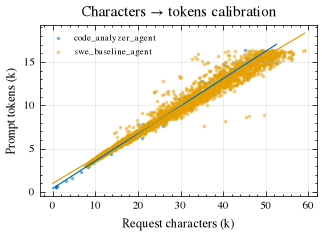

In [5]:
with run.phase("load"):
    steps = load_steps(*inputs)
    results = load_results(*inputs)
    calls = acc.model_calls(steps)
    fits = acc.fit_chars_to_tokens(calls)
fit_table = pl.DataFrame([f.__dict__ for f in fits.values()])
display(fit_table)
display(
    Markdown(
        f"{results.height} task runs · {calls.height} model calls · "
        f"{int(calls['overflow'].sum())} rejected for exceeding the 32k window"
    )
)

fig, ax = plotting.figure("single")
ok = calls.filter(pl.col("prompt_tokens").is_not_null())
for agent, g in ok.group_by("agent"):
    ax.scatter(g["chars"] / 1e3, g["prompt_tokens"] / 1e3, s=2, alpha=0.4, label=agent[0])
    f = fits[agent[0]]
    xs = np.linspace(0, float(g["chars"].max()), 50)
    ax.plot(xs / 1e3, (f.tokens_per_char * xs + f.intercept) / 1e3, lw=0.8)
ax.set(
    xlabel="Request characters (k)",
    ylabel="Prompt tokens (k)",
    title="Characters → tokens calibration",
)
ax.legend(fontsize=6)
plotting.save_fig(fig, "e2_char_token_fit", exp_dir=EXP_DIR, run=run)

## 4 · Compute view: what the GPU processed

In [6]:
cv = acc.compute_view(calls)
compute_totals = (
    cv.select(
        pl.col("cached_tokens").sum().alias("prompt: cache hit"),
        pl.col("new").sum().alias("prompt: new"),
        pl.col("recomputed").sum().alias("prompt: recomputed"),
        pl.col("thought_tokens").sum().alias("decode: thinking"),
        pl.col("output_tokens").sum().alias("decode: output"),
    )
    .unpivot(variable_name="category", value_name="tokens")
    .with_columns((pl.col("tokens") / pl.col("tokens").sum()).alias("share"))
)
display(compute_totals)

category,tokens,share
str,i64,f64
"""prompt: cache hit""",22454336,0.78401
"""prompt: new""",2435037,0.085021
"""prompt: recomputed""",3042047,0.106215
"""decode: thinking""",518315,0.018097
"""decode: output""",190617,0.006656


## 5 · Occupancy view: what fills the prompt
Tool outputs are segments that stay in context for every later call of that context.

In [7]:
seg = acc.segments(steps, calls, fits, P.reread_overlap, P.oversized_chars)
display(
    seg.group_by("tool")
    .agg(
        pl.len().alias("n"),
        pl.col("reread").sum(),
        pl.col("truncated").sum(),
        pl.col("oversized").sum(),
        pl.col("chars").median().alias("median_chars"),
        pl.col("lifetime").mean().round(1).alias("mean_lifetime"),
    )
    .sort("n", descending=True)
)

rate = pl.col("agent").replace_strict({a: f.tokens_per_char for a, f in fits.items()}, default=0.25)
occ = calls.filter(~pl.col("overflow")).select(
    ((pl.col("system_chars") + pl.col("user_text")) * rate).sum().alias("instructions + task"),
    (pl.col("model_text") * rate).sum().alias("model text"),
    (pl.col("thought") * rate).sum().alias("stale thinking"),
    (pl.col("tool_call") * rate).sum().alias("tool-call args"),
    (pl.col("tool_output") * rate).sum().alias("tool output"),
)
tool_total = float(occ["tool output"][0])
flag_totals = {
    "re-read": float(seg.filter("reread")["token_steps"].sum()),
    "truncated": float(seg.filter(pl.col("truncated") & ~pl.col("reread"))["token_steps"].sum()),
    "oversized": float(
        seg.filter(pl.col("oversized") & ~pl.col("truncated") & ~pl.col("reread"))[
            "token_steps"
        ].sum()
    ),
}
occupancy = pl.DataFrame(
    {
        "segment": [
            "instructions + task",
            "model text",
            "stale thinking",
            "tool-call args",
            "tool output: fresh",
            "tool output: re-read",
            "tool output: truncated",
            "tool output: oversized",
        ],
        "tokens": [
            float(occ[c][0])
            for c in ("instructions + task", "model text", "stale thinking", "tool-call args")
        ]
        + [
            max(0.0, tool_total - sum(flag_totals.values())),
            flag_totals["re-read"],
            flag_totals["truncated"],
            flag_totals["oversized"],
        ],
    }
).with_columns((pl.col("tokens") / pl.col("tokens").sum()).alias("share"))
display(occupancy)

tool,n,reread,truncated,oversized,median_chars,mean_lifetime
str,u32,u32,u32,u32,f64,f64
"""run_command""",1332,23,35,0,158.0,10.6
"""read_file""",966,151,381,0,3500.5,9.6
"""edit_file""",232,0,0,0,417.0,9.3
"""write_file""",215,0,0,0,58.0,10.4
"""submit_patch""",53,0,0,0,56.0,2.4
"""search_similar_code""",20,0,0,1,165.0,6.3
"""get_status""",12,0,0,0,261.0,0.9
"""get_code_neighbors""",8,0,0,0,266.0,11.2


segment,tokens,share
str,f64,f64
"""instructions + task""",8.7090e6,0.347816
"""model text""",422.863148,0.000017
"""stale thinking""",3.9751e6,0.158754
"""tool-call args""",1.3192e6,0.052686
"""tool output: fresh""",4.9084e6,0.196028
"""tool output: re-read""",787159.453844,0.031437
"""tool output: truncated""",5.3399e6,0.213262
"""tool output: oversized""",0.0,0.0


## 6 · H2 test
Per-task waste shares; 95% CIs from a bootstrap over tasks stratified by repo.

In [8]:
tasks = acc.per_task(cv, seg, calls, fits).with_columns(
    pl.col("instance_id").str.replace(r"_\d+$", "").alias("repo")
)
tasks = tasks.join(results.select(*acc.KEY, "resolved", "end_reason"), on=acc.KEY, how="left")
tasks.write_parquet(run.dir / "per_task.parquet")

upper = stats.bootstrap_ci(tasks["waste_share_upper"], strata=tasks["repo"], seed=cfg.seed)
lower = stats.bootstrap_ci(tasks["waste_share_lower"], strata=tasks["repo"], seed=cfg.seed)
parts = {
    c: stats.bootstrap_ci(tasks[c], strata=tasks["repo"], seed=cfg.seed)
    for c in ("reread_share", "truncated_share", "recomputed_share")
}
if lower.lo > P.h2_supported_above:
    verdict = "SUPPORTED"
elif upper.hi < P.h2_falsified_below:
    verdict = "FALSIFIED"
else:
    verdict = "INCONCLUSIVE"
h2 = {
    "verdict": verdict,
    "n_tasks": tasks.height,
    "waste_upper": str(upper),
    "waste_lower": str(lower),
    **{k: str(v) for k, v in parts.items()},
}
run.event("h2", **h2)
run.log_metrics(
    {
        "waste_upper": upper.point,
        "waste_lower": lower.point,
        **{k: v.point for k, v in parts.items()},
    }
)
display(
    Markdown(
        f"**H2: {verdict}** (n={tasks.height} task runs)  \n"
        f"waste share, upper bound (sum): {upper}  \nlower bound (largest category): {lower}  \n"
        + "  \n".join(f"{k}: {v}" for k, v in parts.items())
    )
)
display(
    tasks.group_by("tag").agg(
        pl.len().alias("n"),
        pl.col("waste_share_upper").mean(),
        pl.col("waste_share_lower").mean(),
        pl.col("cache_hit_rate").mean(),
        pl.col("overflow_calls").sum(),
    )
)

**H2: INCONCLUSIVE** (n=165 task runs)  
waste share, upper bound (sum): 0.337 [0.304, 0.372] (n=165)  
lower bound (largest category): 0.244 [0.221, 0.267] (n=165)  
reread_share: 0.021 [0.015, 0.028] (n=165)  
truncated_share: 0.206 [0.184, 0.228] (n=165)  
recomputed_share: 0.111 [0.090, 0.133] (n=165)

tag,n,waste_share_upper,waste_share_lower,cache_hit_rate,overflow_calls
str,u32,f64,f64,f64,u32
"""t6min""",165,0.337176,0.244028,0.776921,126


## 7 · Paper figures

PosixPath('<repo>/experiments/E2_token_accounting/figures/e2_token_accounting.pdf')

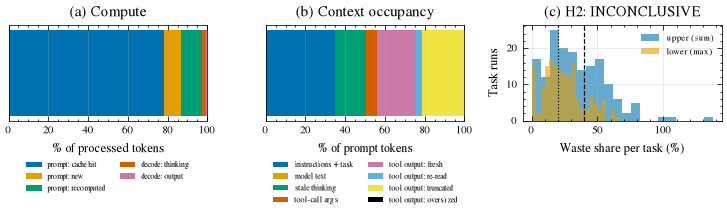

In [9]:
fig, axes = plotting.figure("double", aspect=0.36, ncols=3)
# (a) compute view
ax = axes[0]
left = 0.0
for row in compute_totals.iter_rows(named=True):
    ax.barh([0], [row["share"] * 100], left=[left], label=row["category"])
    left += row["share"] * 100
ax.set(xlim=(0, 100), yticks=[], xlabel="% of processed tokens", title="(a) Compute")
ax.legend(fontsize=5, loc="upper center", bbox_to_anchor=(0.5, -0.35), ncol=2, frameon=False)
# (b) occupancy view
ax = axes[1]
left = 0.0
for row in occupancy.iter_rows(named=True):
    ax.barh([0], [row["share"] * 100], left=[left], label=row["segment"])
    left += row["share"] * 100
ax.set(xlim=(0, 100), yticks=[], xlabel="% of prompt tokens", title="(b) Context occupancy")
ax.legend(fontsize=5, loc="upper center", bbox_to_anchor=(0.5, -0.35), ncol=2, frameon=False)
# (c) per-task waste distribution against the pre-registered thresholds
ax = axes[2]
ax.hist(tasks["waste_share_upper"] * 100, bins=20, alpha=0.6, label="upper (sum)")
ax.hist(tasks["waste_share_lower"] * 100, bins=20, alpha=0.6, label="lower (max)")
for thr, style in ((P.h2_falsified_below, ":"), (P.h2_supported_above, "--")):
    ax.axvline(thr * 100, color="k", ls=style, lw=0.8)
ax.set(xlabel="Waste share per task (%)", ylabel="Task runs", title=f"(c) H2: {verdict}")
ax.legend(fontsize=6)
fig.tight_layout()
plotting.save_fig(fig, "e2_token_accounting", exp_dir=EXP_DIR, run=run)

PosixPath('<repo>/experiments/E2_token_accounting/figures/e2_context_growth.pdf')

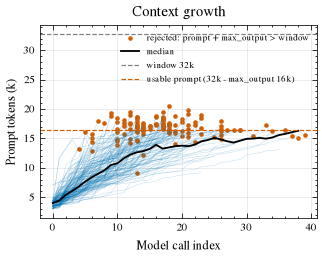

In [10]:
# Context growth: prompt size per call for every root-agent context, 32k limit, overflows.
fig, ax = plotting.figure("single", aspect=0.7)
root_agent = calls.group_by("agent").len().sort("len", descending=True)["agent"][0]
rc = calls.filter(pl.col("agent") == root_agent)
est = rc.with_columns(
    pl.coalesce(
        "prompt_tokens",
        pl.col("chars") * fits[root_agent].tokens_per_char + fits[root_agent].intercept,
    ).alias("p")
)
for _, g in est.group_by(acc.CTX):
    ax.plot(g["call_idx"], g["p"] / 1e3, lw=0.3, alpha=0.25, color=plotting.PALETTE[0])
of = est.filter("overflow")
ax.scatter(of["call_idx"], of["p"] / 1e3, s=4, color=plotting.PALETTE[3],
           label="rejected: prompt + max_output > window")
med = (
    est.filter(~pl.col("overflow")).group_by("call_idx").agg(pl.col("p").median()).sort("call_idx")
)
ax.plot(med["call_idx"], med["p"] / 1e3, lw=1.2, color="k", label="median")
window = cfg.serving.max_model_len
ax.axhline(window / 1e3, ls="--", lw=0.8, color="grey", label=f"window {window // 1024}k")
usable = window - P.reserved_output_tokens
ax.axhline(usable / 1e3, ls="--", lw=0.8, color=plotting.PALETTE[3],
           label=f"usable prompt ({window // 1024}k - max_output {P.reserved_output_tokens // 1024}k)")
ax.set(xlabel="Model call index", ylabel="Prompt tokens (k)", title="Context growth")
ax.legend(fontsize=6)
plotting.save_fig(fig, "e2_context_growth", exp_dir=EXP_DIR, run=run)

## 8 · Teardown

In [11]:
tables = EXP_DIR / "tables"
tables.mkdir(exist_ok=True)
compute_totals.write_csv(tables / "e2_compute_view.csv")
occupancy.write_csv(tables / "e2_occupancy_view.csv")
fit_table.write_csv(tables / "e2_char_token_fit.csv")
pl.DataFrame([h2]).write_csv(tables / "e2_h2_test.csv")
run.finish()
print((run.dir / "summary.json").read_text())

🏃 View run 20260925T163354Z-512f5ef3-de88 at: http://127.0.0.1:5000/#/experiments/3/runs/2376bc7176e341f595bb2d282e146e31
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/3
{
  "run_id": "20260925T163354Z-512f5ef3-de88",
  "status": "FINISHED",
  "wall_s": 4.834,
  "monitor_overhead_s": {
    "host": 0.017
  },
  "gpu_energy_kwh": null,
  "codecarbon": null
}
